In [67]:
import json
import matplotlib.pyplot as plt
import numpy as np

with open("results.json",'r') as f:
    log = json.load(f)
    

num_sizes  = np.array([int(size) for size in log['numeric'].keys()])
num_values = np.array([[list(log['numeric'][size]['I_x']),
                    list(log['numeric'][size]['I_y']),
                    list(log['numeric'][size]['I_xy']),
                    list(log['numeric'][size]['A'])
                   ] for size in log['numeric'].keys()])

num_times  = np.array([log['numeric'][size]['time']/num_values.shape[-1] for size in log['numeric'].keys()])


dd_sizes  = np.array([int(size) for size in log['data-driven'].keys()])
dd_values = np.array([[log['data-driven'][size]['I_x'],
                       log['data-driven'][size]['I_y'],
                       log['data-driven'][size]['I_xy'],
                       log['data-driven'][size]['A']
                      ] for size in log['data-driven'].keys()])
dd_times  = [log['data-driven'][size]['time']/dd_values.shape[-1] for size in log['data-driven'].keys()]



num_values= num_values[:,:,:500]
dd_values = dd_values[:,:,:500]

num_times = num_times*2
dd_times = dd_times*2


ref = num_values[-1]

MAE = np.average(abs((ref-num_values)),axis=2)
MSE = np.average(((ref-num_values))**2,axis=2)

dd_MAE = np.average(abs((ref-dd_values)),axis=2)
dd_MSE = np.average(((ref-dd_values))**2,axis=2)

ValueError: operands could not be broadcast together with shapes (4,500) (2,4,1000) 

### Plot with (125,125) and (175,175)

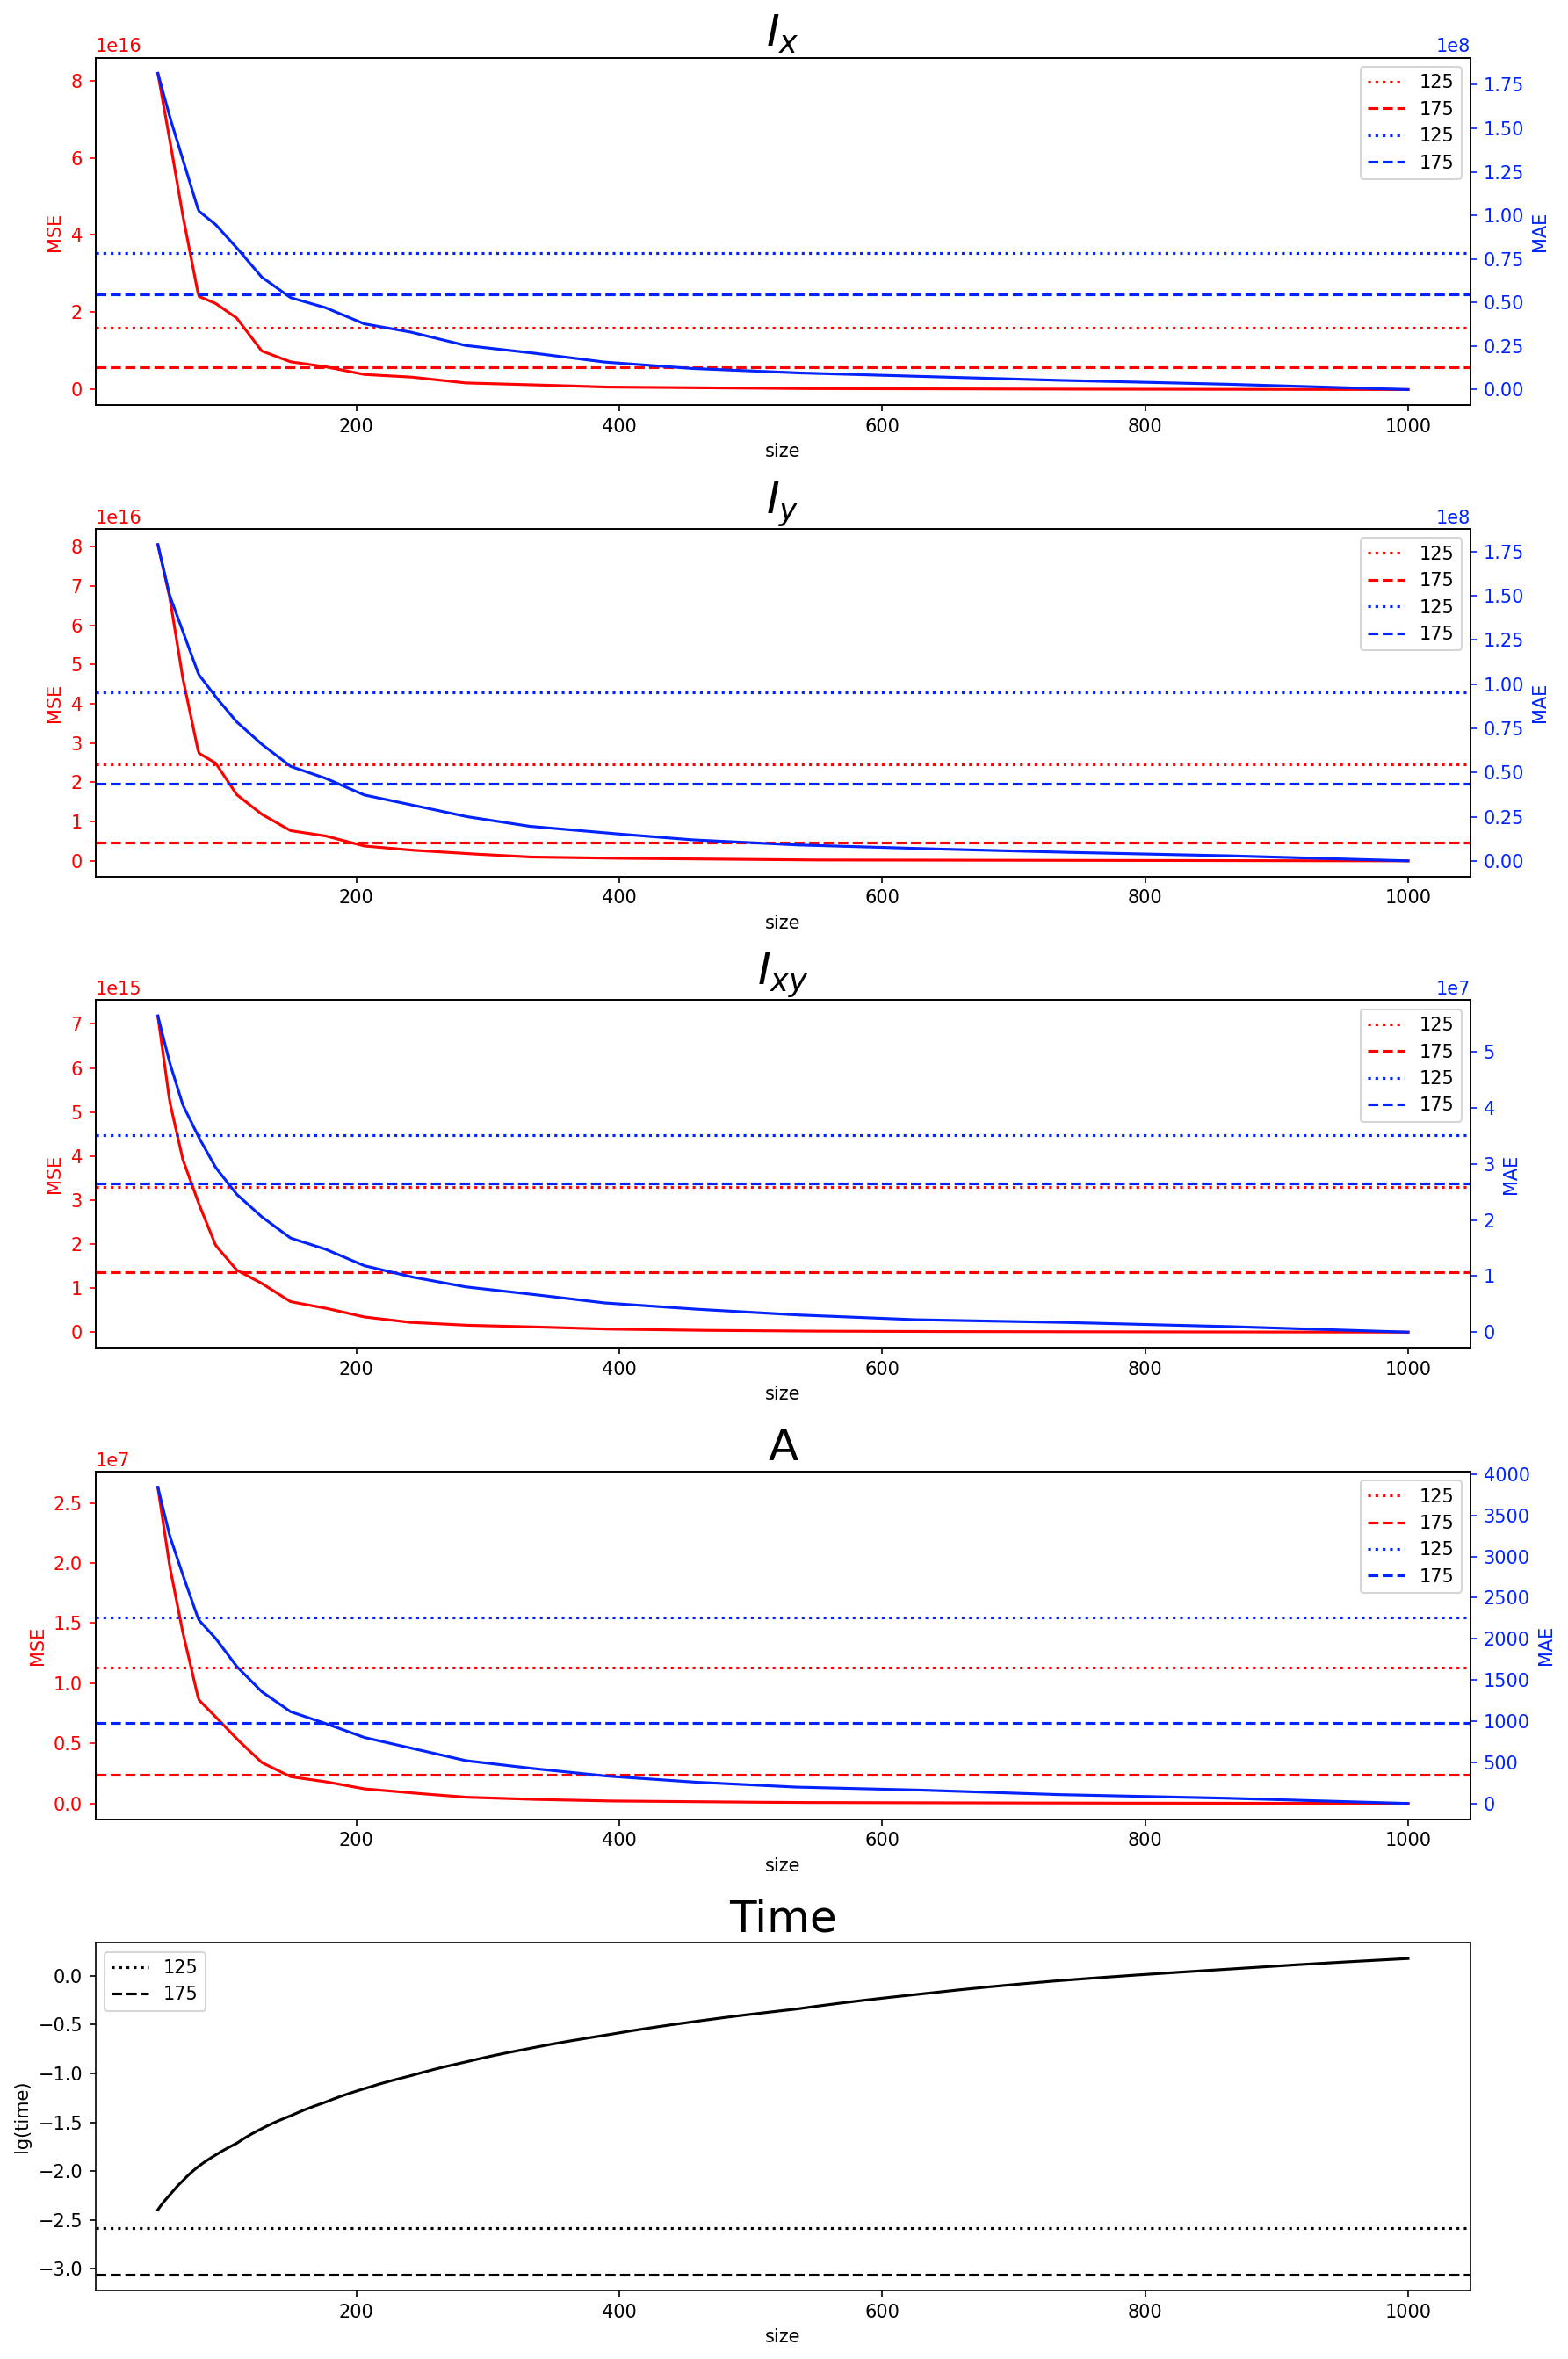

In [58]:
# interpolation
new_sizes = np.linspace(num_sizes[0],num_sizes[-1],1000)
MAE = np.array([np.interp(new_sizes,num_sizes,mae,1000) for mae in MAE.T]).T
MSE = np.array([np.interp(new_sizes,num_sizes,mae,1000) for mae in MSE.T]).T
times = np.interp(new_sizes,num_sizes,num_times,1000)
sizes = new_sizes

fig, ax = plt.subplots(5,1,figsize=(12,18),dpi=150)

labels = [r'$I_x$',r'$I_y$',r'$I_{xy}$','A']


for i,(label,mse,mae,dd_mse,dd_mae) in enumerate(zip(labels,MSE.T,MAE.T,dd_MSE.T,dd_MAE.T)):
    
    # PRINT MSE
    ax[i].plot(sizes,mse,color='#FF0000')
    ln1 = ax[i].axhline(y=dd_mse[0], color='#FF0000',label='125', linestyle=':')
    ln2 = ax[i].axhline(y=dd_mse[1], color='#FF0000',label='175', linestyle='--')
    ax[i].set_title(label,fontsize=24)
    ax[i].set_xlabel('size')
    ax[i].tick_params(axis="y", colors='#FF0000')
    ax[i].set_ylabel('MSE',color='#FF0000')
    """
    # PRINT MSE CROSSES
    index = np.argwhere(np.diff(np.sign(dd_mse[0] - mse))).flatten()
    print(sizes[index],dd_mse[0])
    ax[i].plot(sizes[index],dd_mse[0],'o',color='#000000')
    ax[i].plot(sizes[index],dd_mse[0],'.',color='#FF0000')
    ax[i].text(sizes[index],dd_mse[0], f" {int(sizes[index])}", ha='left',color='#000000',fontsize=9,rotation=45)
    
    index = np.argwhere(np.diff(np.sign(dd_mse[1] - mse))).flatten()
    ax[i].plot(sizes[index],dd_mse[1],'o',color='#000000')
    ax[i].plot(sizes[index],dd_mse[1],'.',color='#FF0000')
    ax[i].text(sizes[index],dd_mse[1], f" {int(sizes[index])}", ha='left',color='#000000',fontsize=9,rotation=45)
    ax[i].set_xlabel('size')
    """
    # PRINT MAE
    twin_ax = ax[i].twinx()
    twin_ax.plot(sizes,mae,color='#0023FF')
    ln3 = twin_ax.axhline(y=dd_mae[0], color='#0023FF',label='125', linestyle=':')
    ln4 = twin_ax.axhline(y=dd_mae[1], color='#0023FF',label='175', linestyle='--')
    twin_ax.tick_params(axis="y", colors='#0023FF')
    twin_ax.set_ylabel('MAE',color='#0023FF')
    """
    # PRINT MSE CROSSES
    index = np.argwhere(np.diff(np.sign(dd_mae[0] - mae))).flatten()
    twin_ax.plot(sizes[index],dd_mae[0],'o',color='#000000')
    twin_ax.plot(sizes[index],dd_mae[0],'.',color='#0023FF')
    twin_ax.text(sizes[index],dd_mae[0], f" {int(sizes[index])}", ha='left',color='#000000',fontsize=9,rotation=45)
    
    index = np.argwhere(np.diff(np.sign(dd_mae[1] - mae))).flatten()
    twin_ax.plot(sizes[index],dd_mae[1],'o',color='#000000')
    twin_ax.plot(sizes[index],dd_mae[1],'.',color='#0023FF')
    twin_ax.text(sizes[index],dd_mae[1], f" {int(sizes[index])}", ha='left',color='#000000',fontsize=9,rotation=45)
    """
    # COMMON LEGEND
    lns = [ln1,ln2,ln3,ln4]
    ax[i].legend(lns,[l.get_label() for l in lns])

ax[4].axhline(y=np.log10(dd_times[0]), color='#000000',label='125', linestyle=':')
ax[4].axhline(y=np.log10(dd_times[1]), color='#000000',label='175', linestyle='--')

ax[4].legend()
ax[4].plot(sizes,np.log10(times),color='#000000')
ax[4].set_ylabel('lg(time)')
ax[4].set_xlabel('size')
ax[4].set_title('Time',fontsize=24)

fig.tight_layout()

### With all models

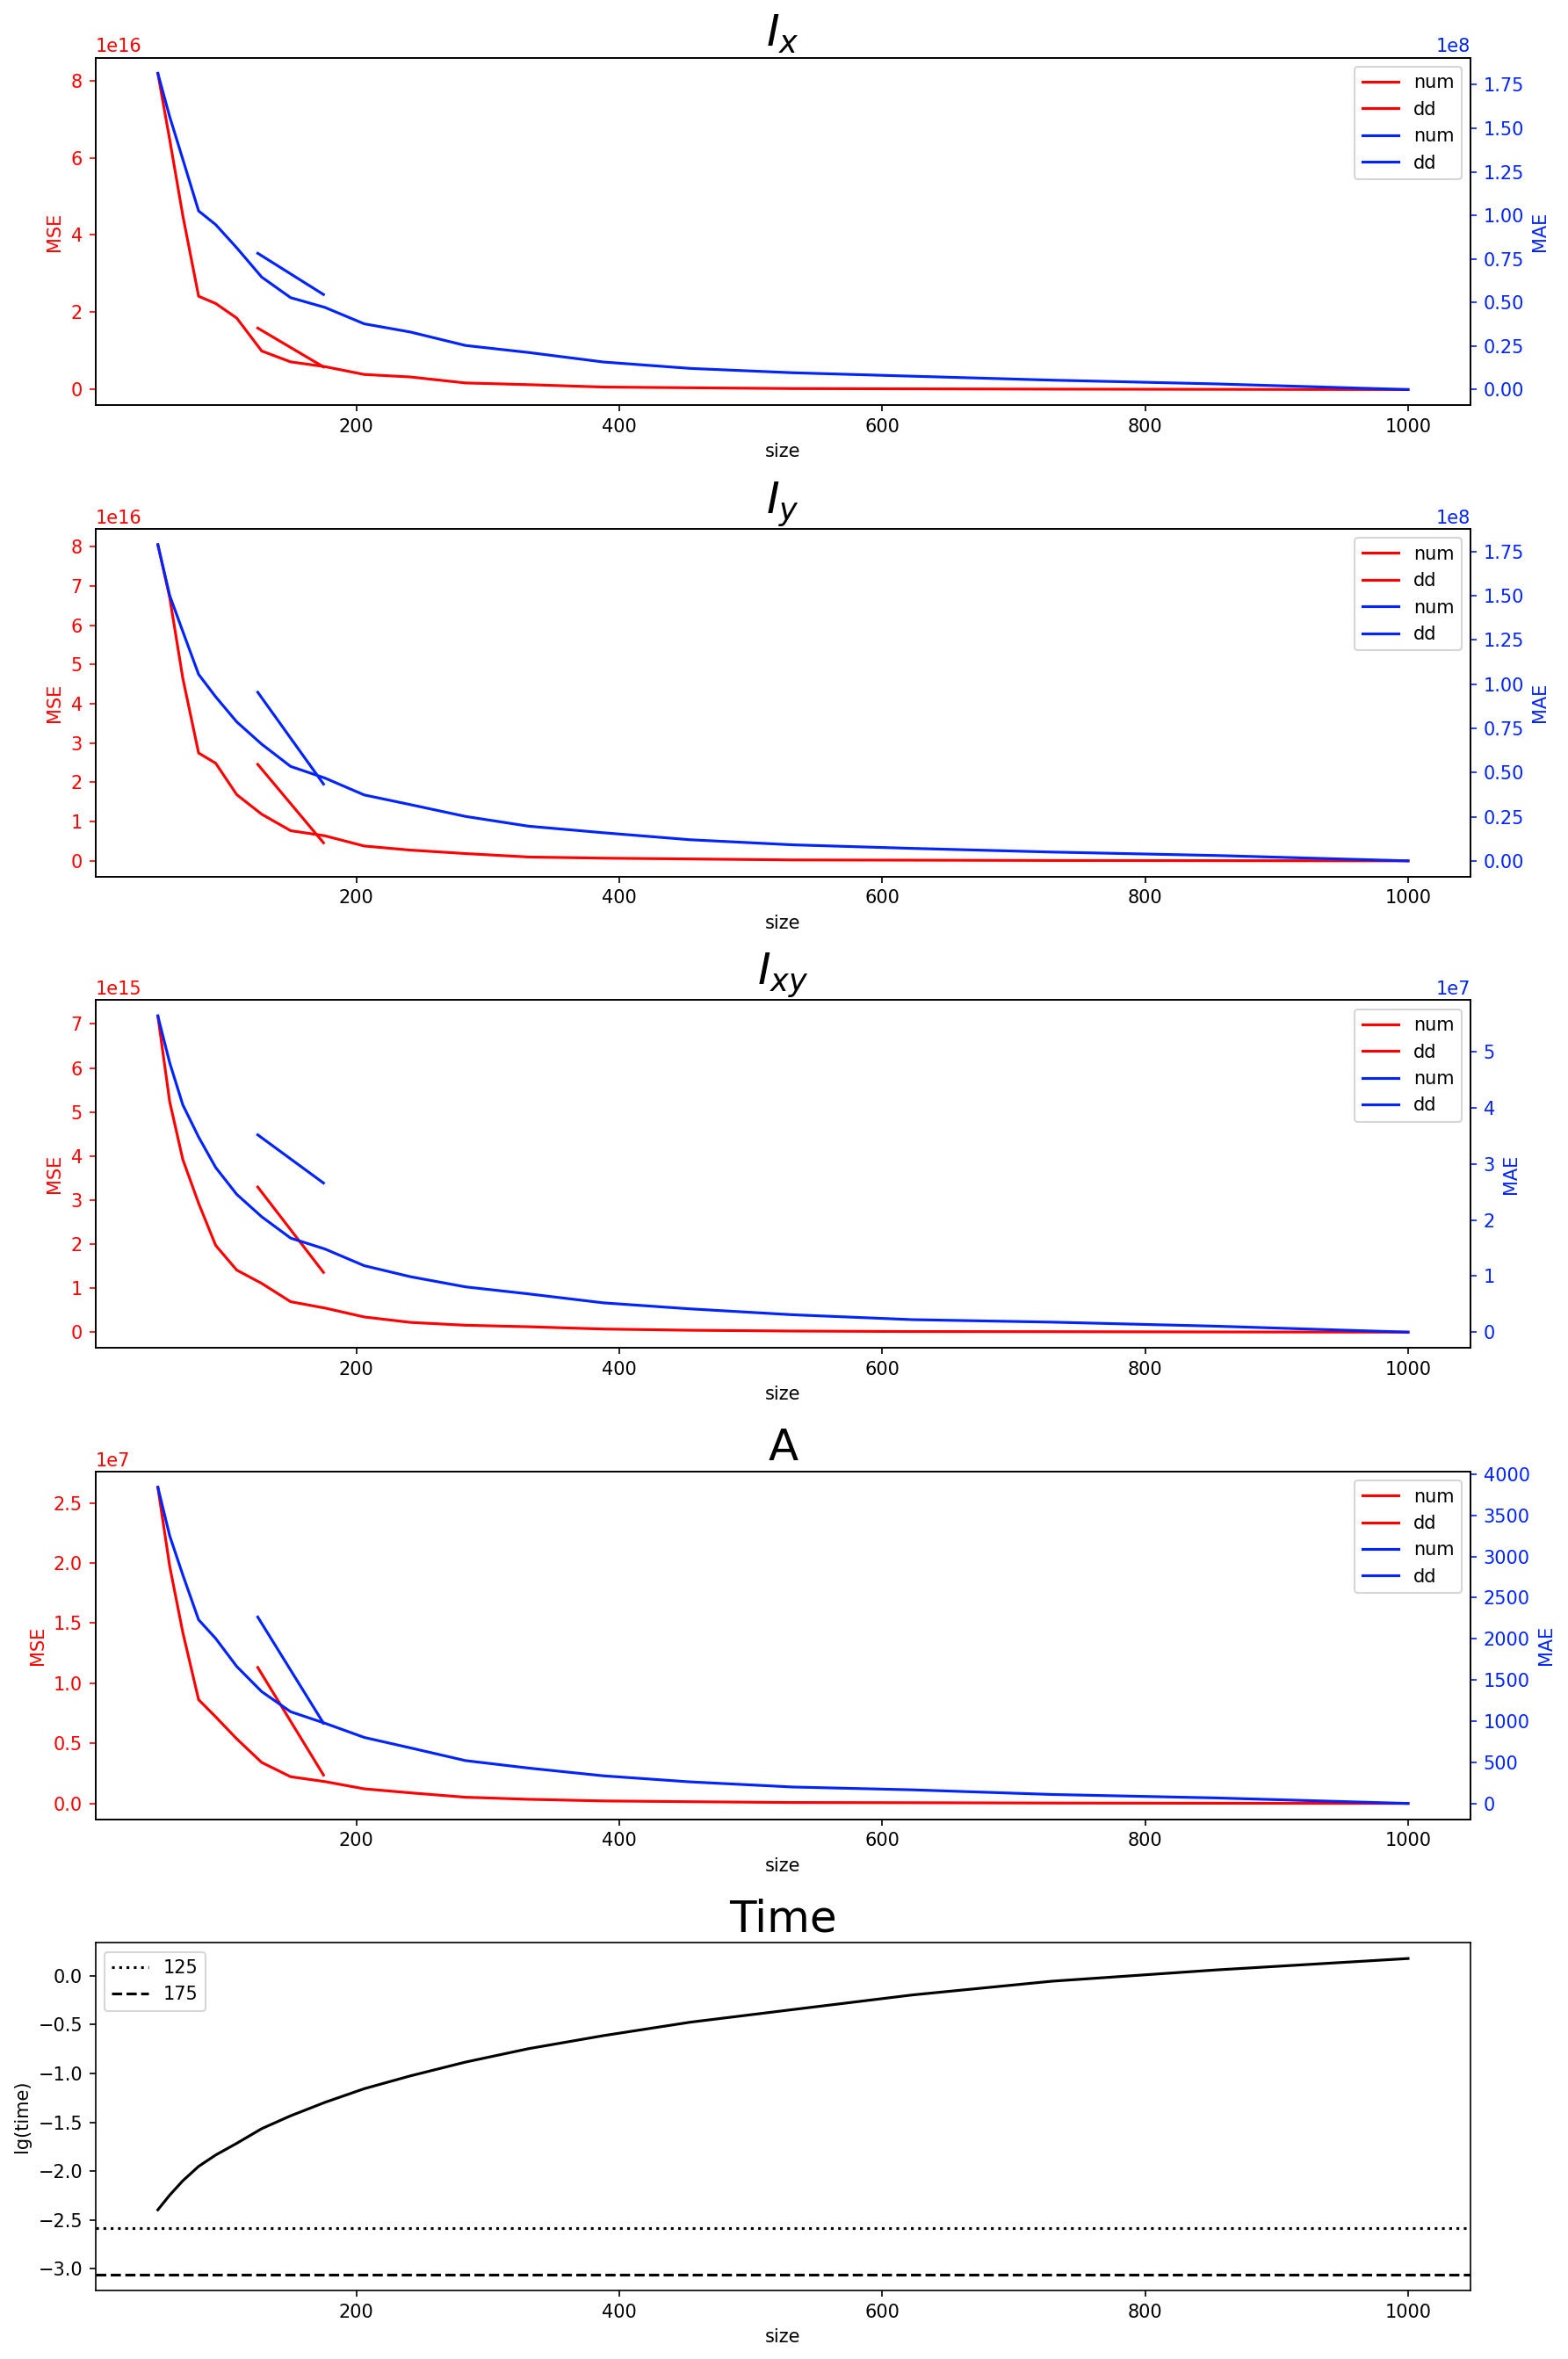

In [64]:
fig, ax = plt.subplots(5,1,figsize=(12,18),dpi=150)

labels = [r'$I_x$',r'$I_y$',r'$I_{xy}$','A']


for i,(label,mse,mae,dd_mse,dd_mae) in enumerate(zip(labels,MSE.T,MAE.T,dd_MSE.T,dd_MAE.T)):
    
    # PRINT MSE
    ln1 = ax[i].plot(num_sizes,mse,label='num',color='#FF0000')
    ln2 = ax[i].plot(dd_sizes,dd_mse,label='dd',color='#FF0000')
    ax[i].tick_params(axis="y", colors='#FF0000')
    ax[i].set_ylabel('MSE',color='#FF0000')
    
    # CLONE
    twin_ax = ax[i].twinx()
    
    # PRINT MAE
    ln3 = twin_ax.plot(num_sizes,mae,label='num',color='#0023FF')
    ln4 = twin_ax.plot(dd_sizes,dd_mae,label='dd',color='#0023FF')
    twin_ax.tick_params(axis="y", colors='#0023FF')
    twin_ax.set_ylabel('MAE',color='#0023FF')

    # COMMON
    lns = ln1+ln2+ln3+ln4
    ax[i].legend(lns,[l.get_label() for l in lns])
    ax[i].set_title(label,fontsize=24)
    ax[i].set_xlabel('size')

ax[4].axhline(y=np.log10(dd_times[0]), color='#000000',label='125', linestyle=':')
ax[4].axhline(y=np.log10(dd_times[1]), color='#000000',label='175', linestyle='--')

ax[4].legend()
ax[4].plot(num_sizes,np.log10(times),color='#000000')
ax[4].set_ylabel('lg(time)')
ax[4].set_xlabel('size')
ax[4].set_title('Time',fontsize=24)

fig.tight_layout()

128


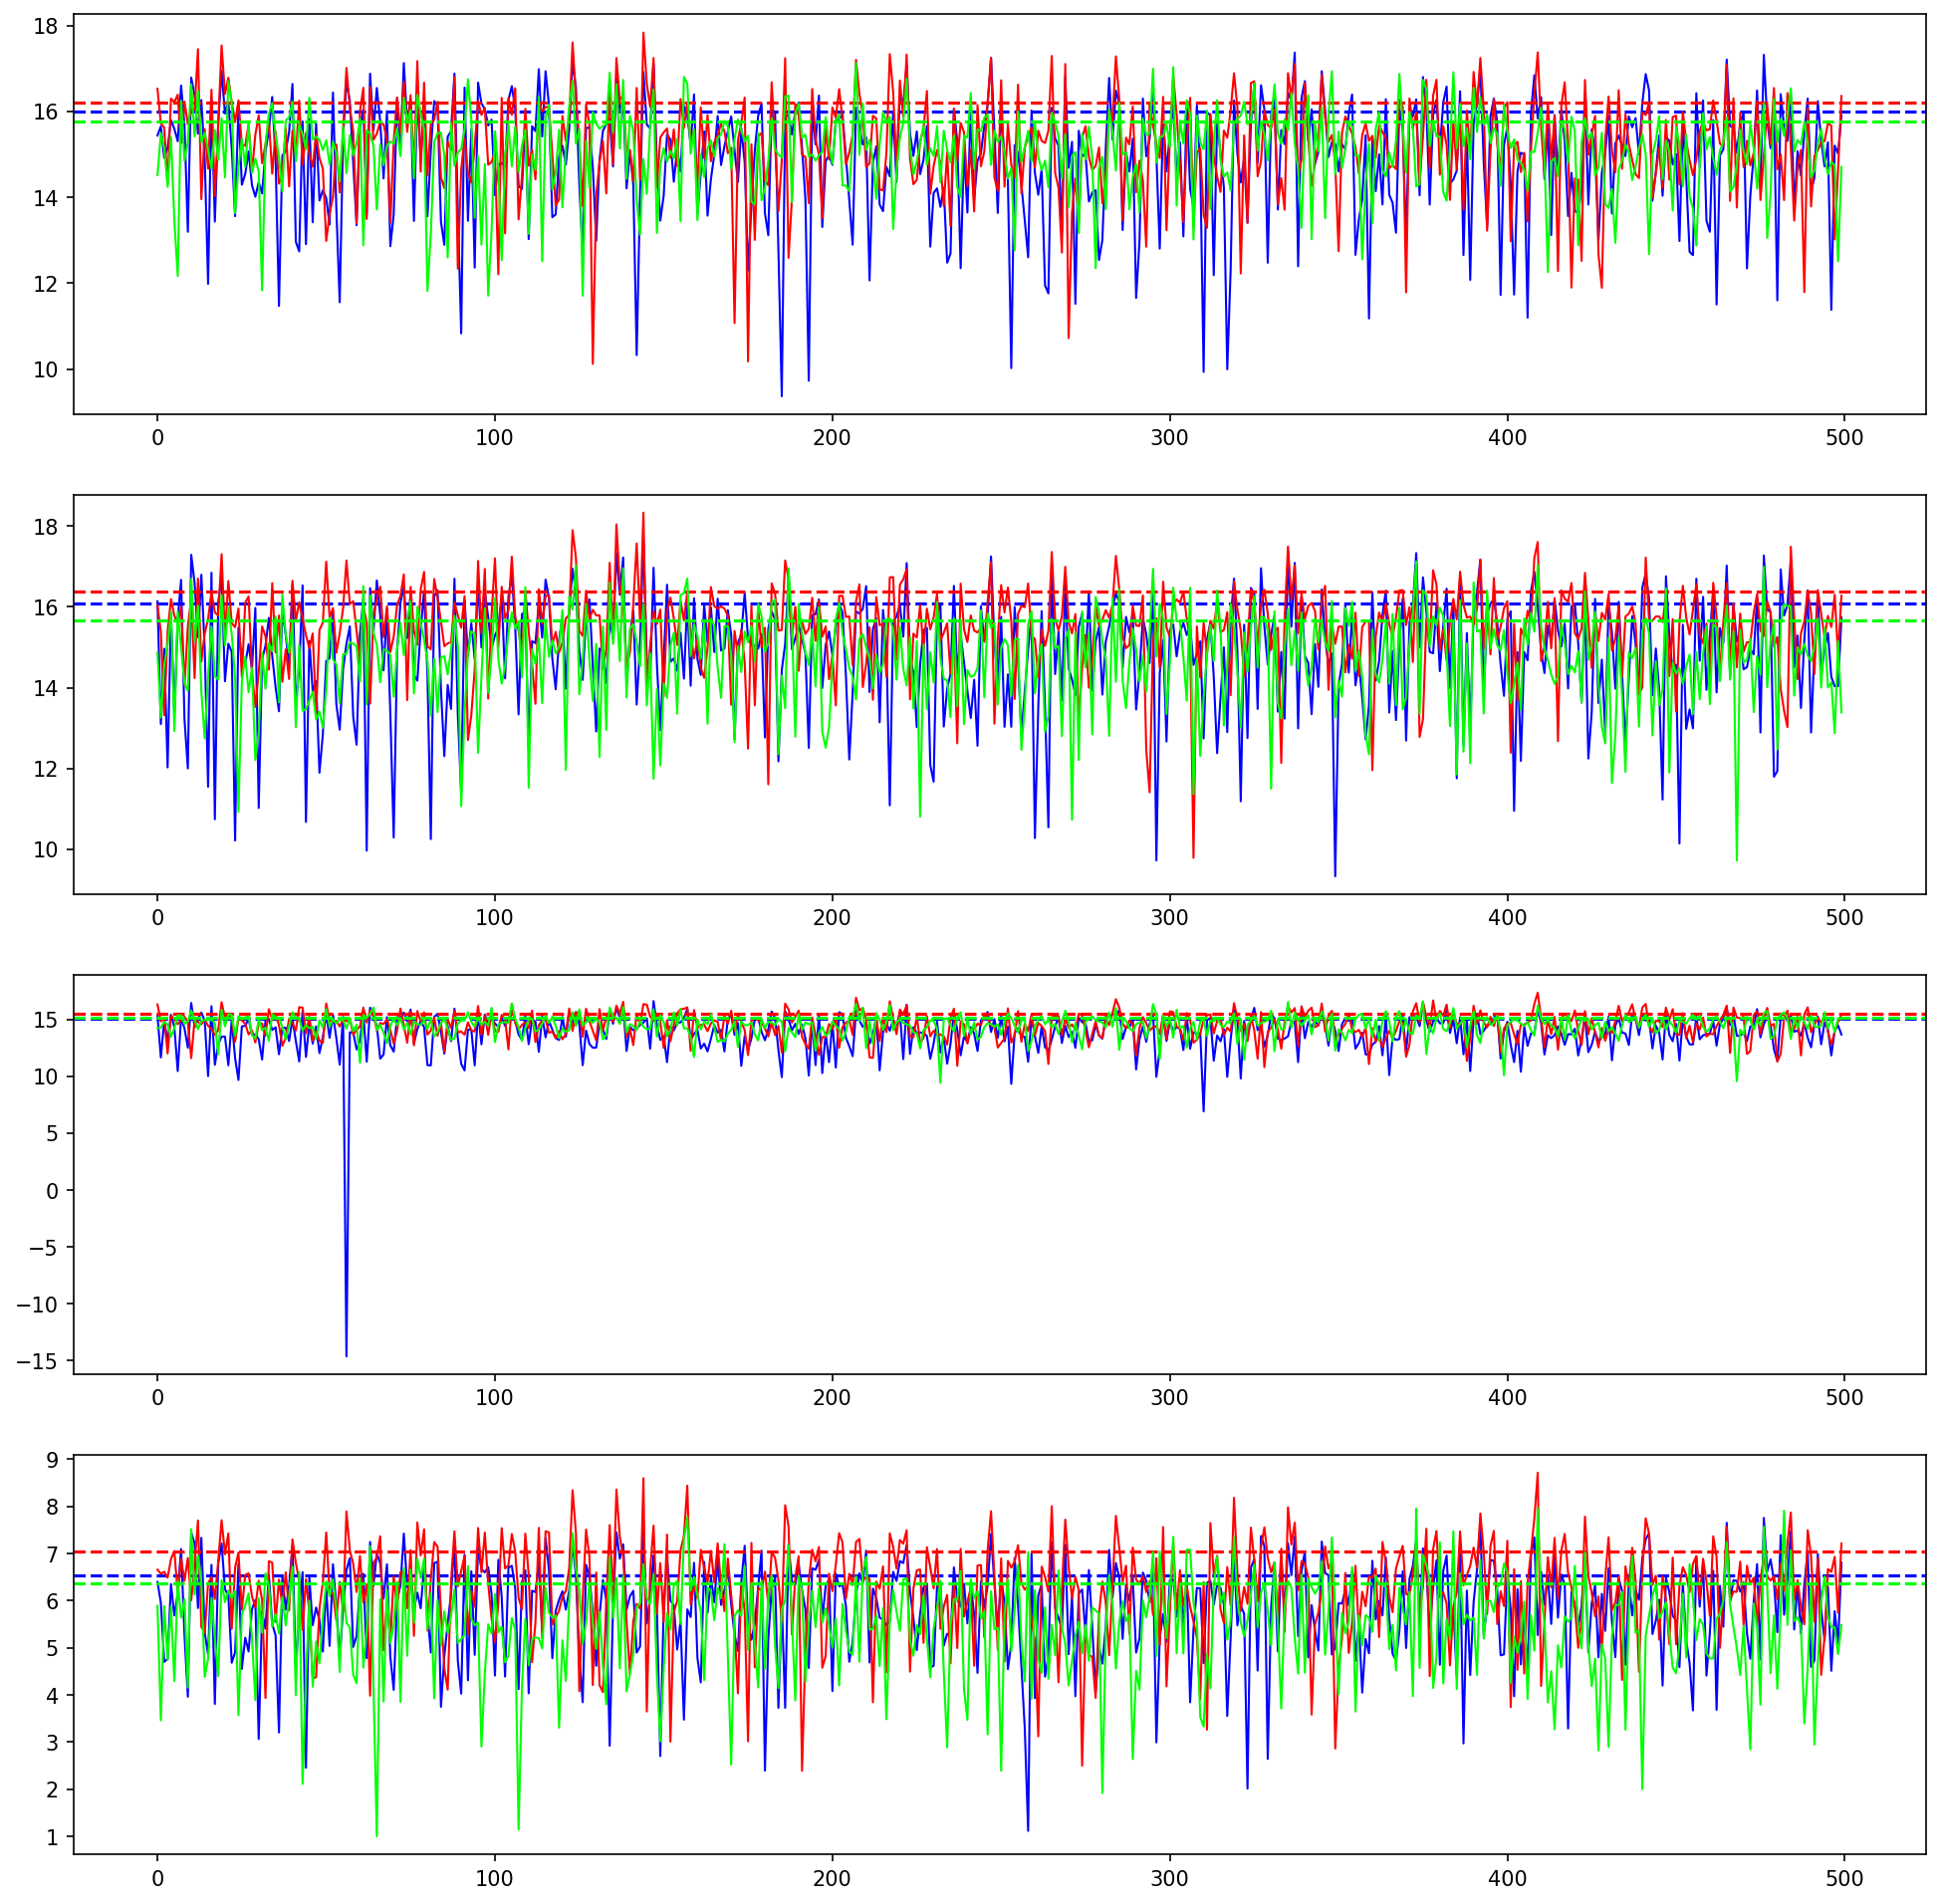

In [287]:
fig, ax = plt.subplots(4,1,figsize=(16,16),dpi=150)

ref = values[-1]

num = 6
print(sizes[num])

for i in range(4):
    ax[i].plot(np.log10((ref[i] - values[num][i])**2),color='#0000FF',lw=1)
    ax[i].axhline(y=np.log10(np.average((ref[i] - values[num][i])**2)), color='#0000FF', linestyle='--')
    
    ax[i].plot(np.log10((ref[i] - dd_values[0][i])**2),color='#FF0000',lw=1)
    ax[i].axhline(y=np.log10(np.average((ref[i] - dd_values[0][i])**2)), color='#FF0000', linestyle='--')
    
    ax[i].plot(np.log10((ref[i] - dd_values[1][i])**2),color='#00FF00',lw=1)
    ax[i].axhline(y=np.log10(np.average((ref[i] - dd_values[1][i])**2)), color='#00FF00', linestyle='--')

206


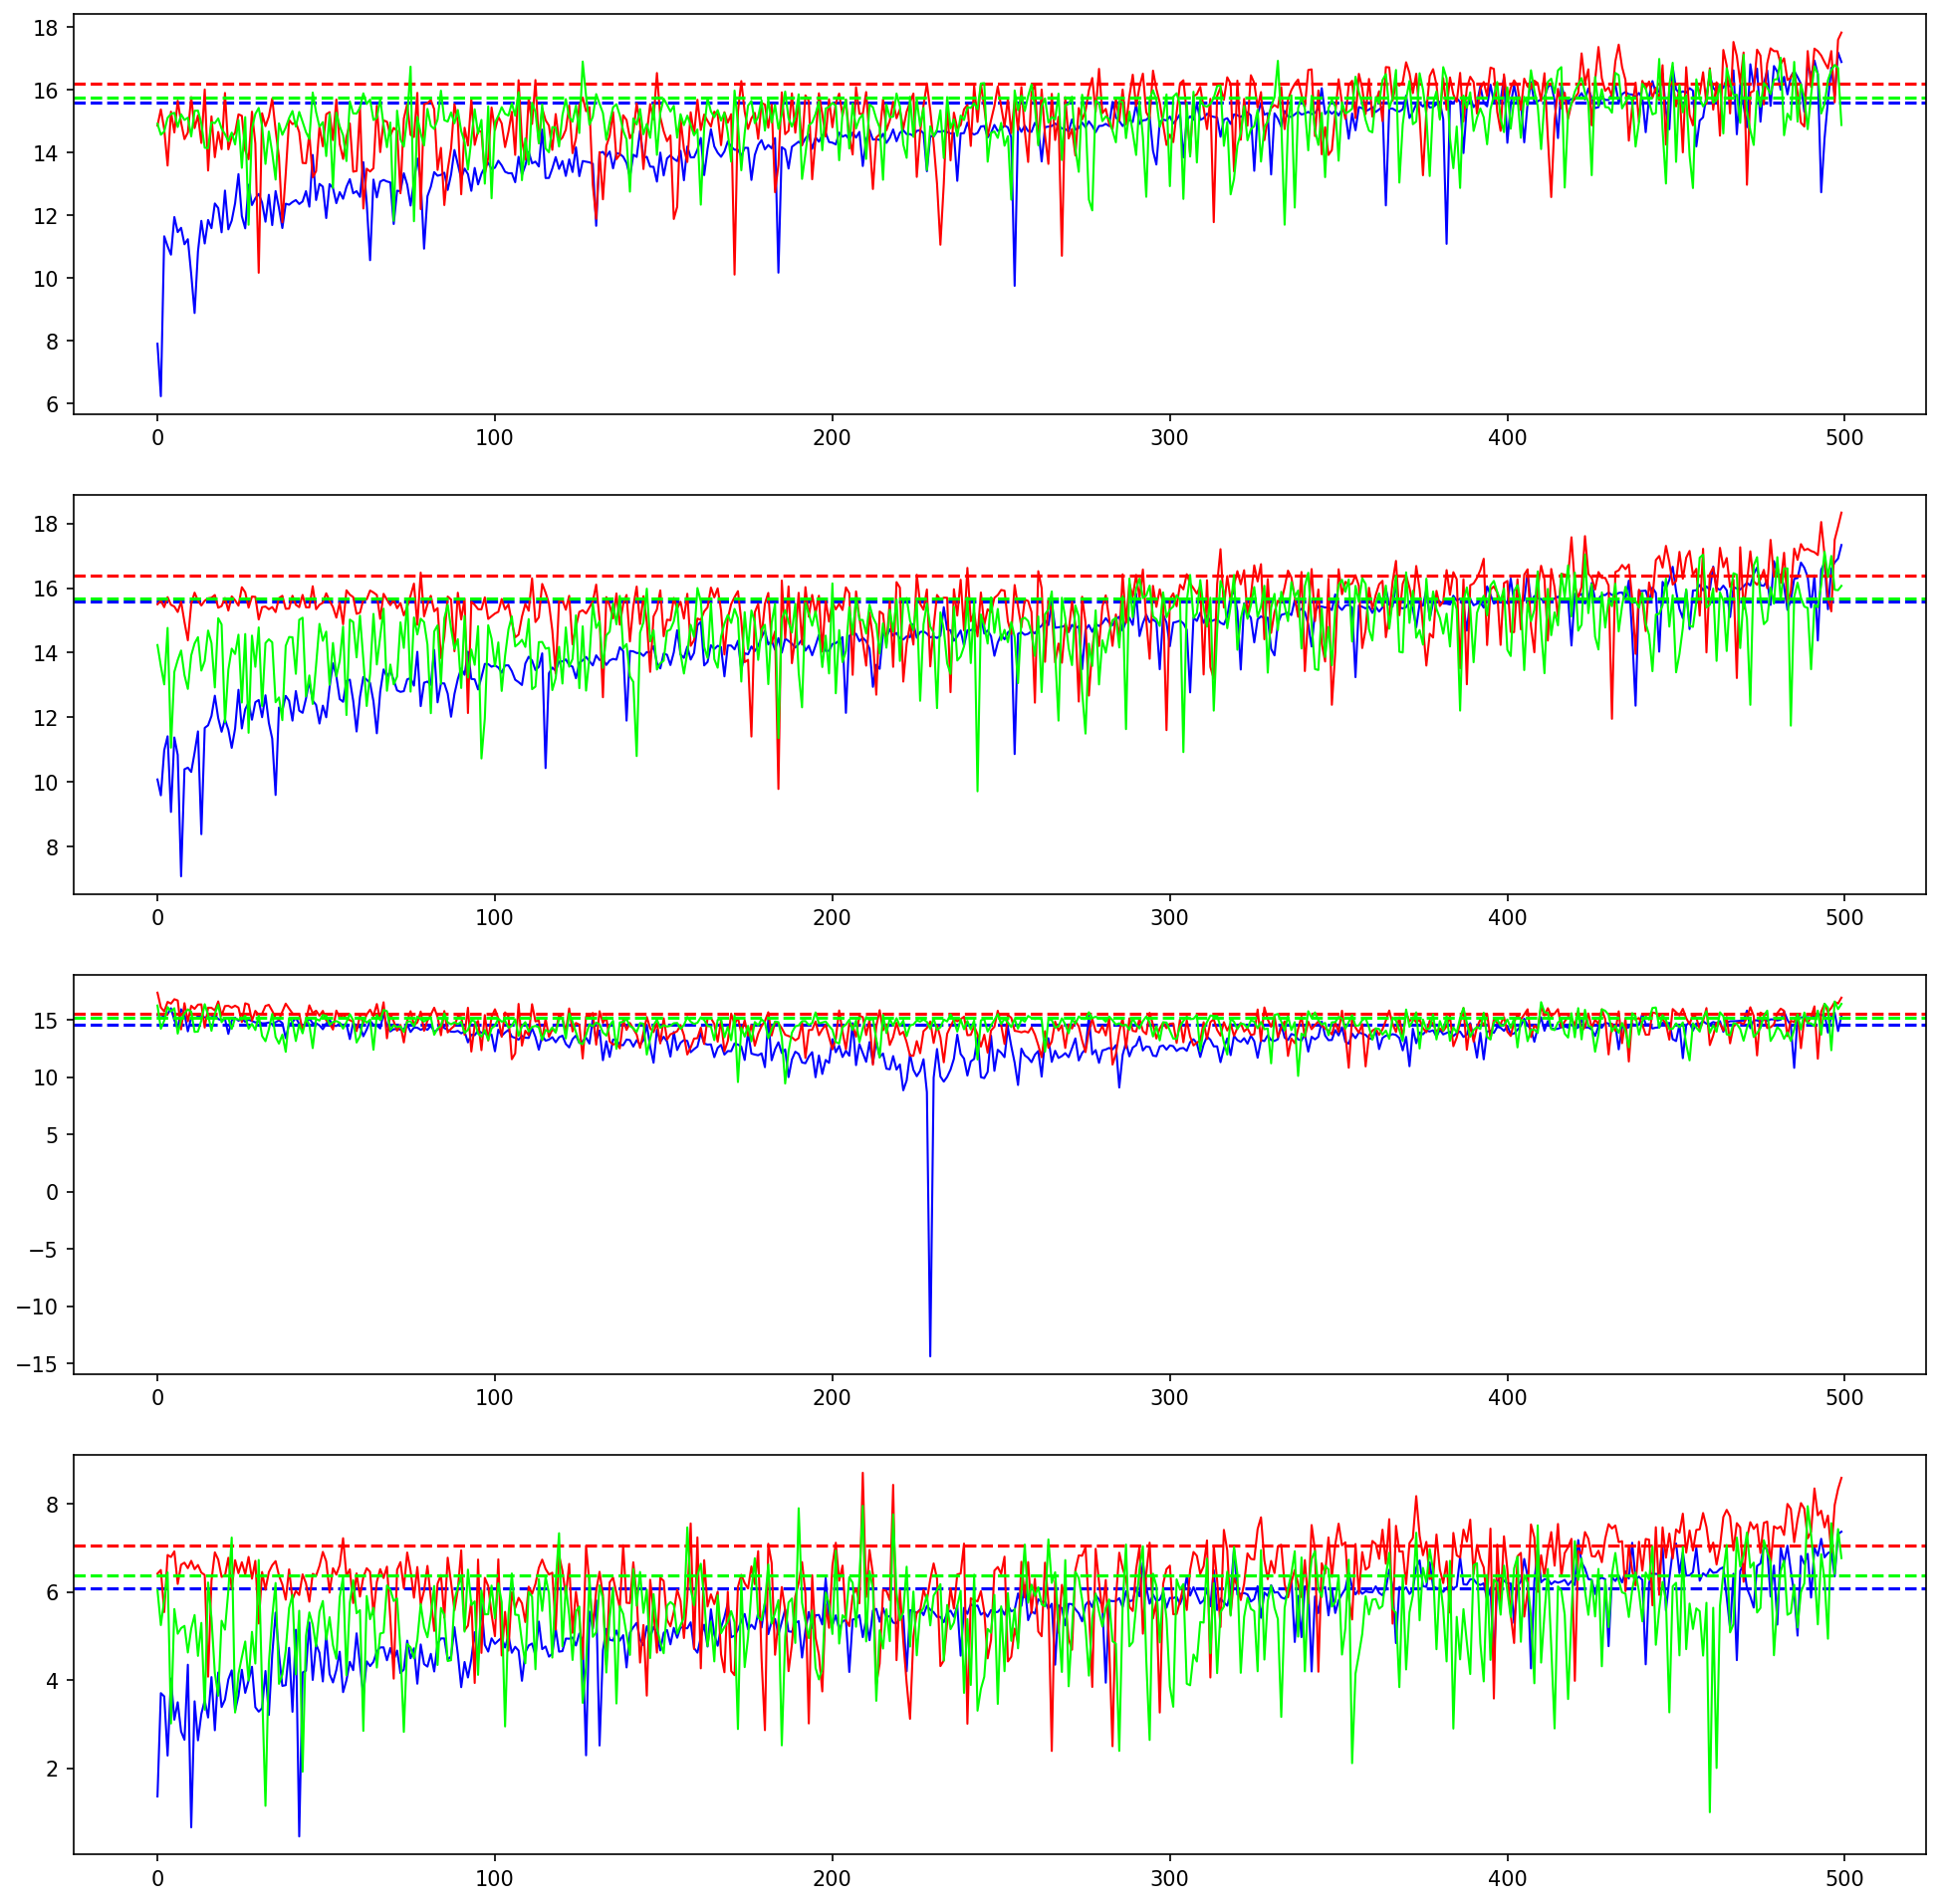

In [281]:
sort = np.argsort(ref,axis=1)

fig, ax = plt.subplots(4,1,figsize=(16,16),dpi=150)

num = 9
print(sizes[num])

for i in range(4):
    ax[i].plot(np.log10((ref[i] - values[num][i])**2)[sort[i]],color='#0000FF',lw=1)
    ax[i].axhline(y=np.log10(np.average((ref[i] - values[num][i])**2)), color='#0000FF', linestyle='--')
    
    ax[i].plot(np.log10((ref[i] - dd_values[0][i])**2)[sort[i]],color='#FF0000',lw=1)
    ax[i].axhline(y=np.log10(np.average((ref[i] - dd_values[0][i])**2)), color='#FF0000', linestyle='--')
    
    ax[i].plot(np.log10((ref[i] - dd_values[1][i])**2)[sort[i]],color='#00FF00',lw=1)
    ax[i].axhline(y=np.log10(np.average((ref[i] - dd_values[1][i])**2)), color='#00FF00', linestyle='--')